In [1]:
# ДЗ 4
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

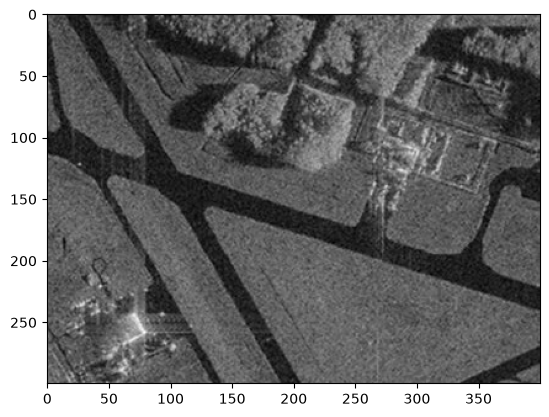

In [3]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

plt.imshow(image_gray, cmap="gray")

35
85
135
185
233
277
333
383
430
479
532
583
632
681
736
619
559
587
606
616
604
599
589
575
550
561
533
522
506
492
470
453
442
420
405
389
367
345
330
307
290
272
258
247
235
219
210
193
153
82
79
70
66
64
59
55
46
41
32
23
53
0


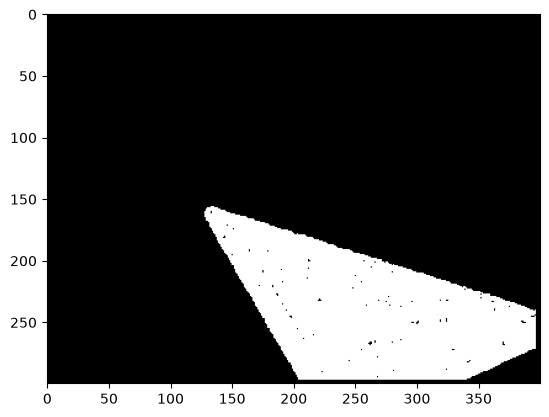

In [4]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
                                                            
    if abs(av_val - img[point]) <= T:
        return True
    
    return False

def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask
        
    return mask*255

seed_point = (250,250)
mask = region_growing(image_gray, seed_point, homo_average, 3, 25)
plt.imshow(mask, cmap="gray")

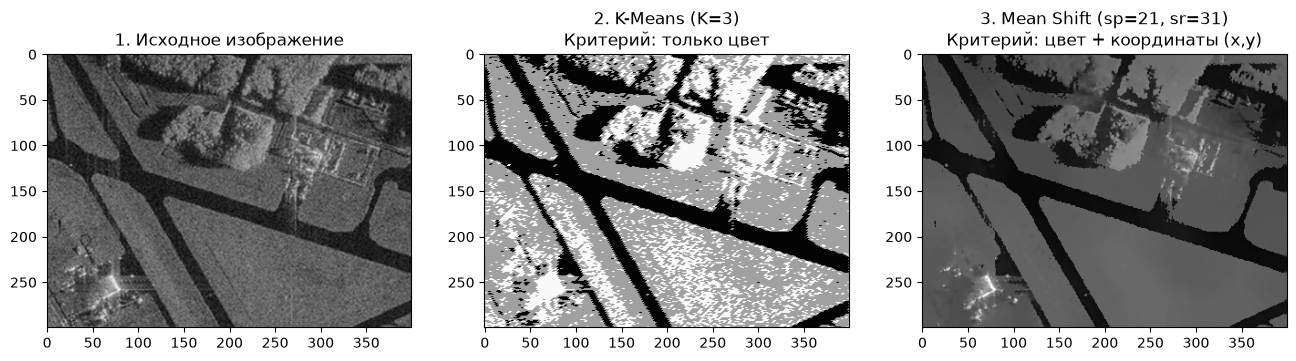

In [18]:
#2
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

z = image_gray.reshape((-1, 3))
z = np.float32(z)

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
K = 3
ret, label, center = cv2.kmeans(z, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

center = np.uint8(center)
res_kmeans = center[label.flatten()].reshape(image_gray.shape)

sp_spatial = 21
sr_color = 31

res_meanshift = cv2.pyrMeanShiftFiltering(image, sp=sp_spatial, sr=sr_color)
res_meanshift_gray = cv2.cvtColor(res_meanshift, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.title("1. Исходное изображение")
plt.imshow(image_gray, cmap='gray')

plt.subplot(1, 3, 2)
plt.title(f"2. K-Means (K={K})\nКритерий: только цвет")
plt.imshow(res_kmeans, cmap='gray')

plt.subplot(1, 3, 3)
plt.title(f"3. Mean Shift (sp={sp_spatial}, sr={sr_color})\nКритерий: цвет + координаты (x,y)")
plt.imshow(res_meanshift_gray, cmap='gray')

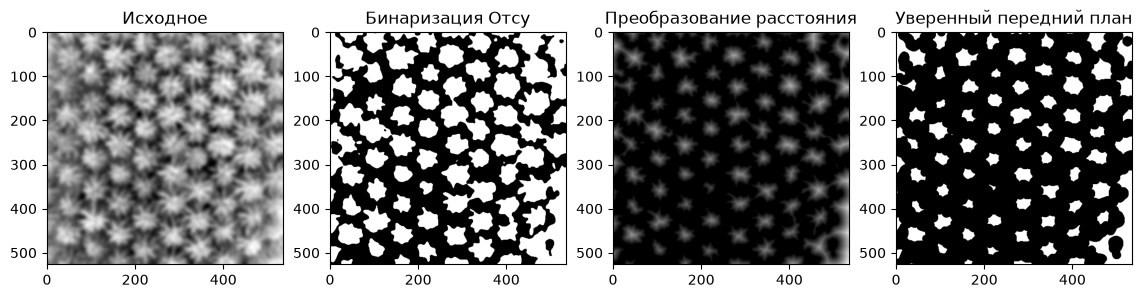

In [11]:
#3
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(image_gray, (25, 25), 0)

plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.title("Исходное")
plt.imshow(blurred, cmap="gray")

ret, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)

plt.subplot(1, 4, 2)
plt.title("Бинаризация Отсу")
plt.imshow(thresh, cmap="gray")

dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 0)

plt.subplot(1, 4, 3)
plt.title("Преобразование расстояния")
plt.imshow(dist, cmap="gray")

ret, sure_fg = cv2.threshold(dist, 0.2 * dist.max(), 255, cv2.THRESH_BINARY) 

plt.subplot(1, 4, 4)
plt.title("Уверенный передний план")
plt.imshow(sure_fg, cmap="gray")

~ 85 пальм


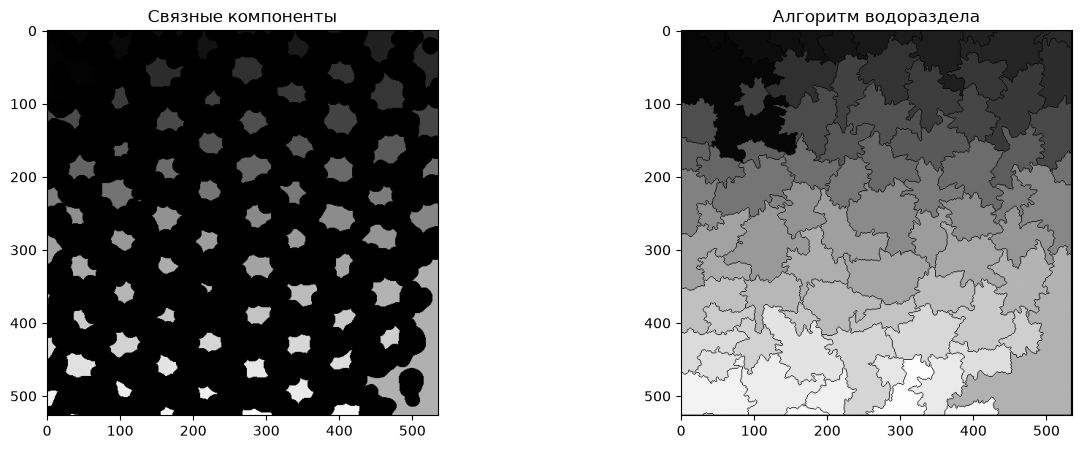

In [12]:
plt.figure(figsize=(15, 5))

sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg)

plt.subplot(1, 2, 1)
plt.title("Связные компоненты")
plt.imshow(markers, cmap="gray")

print("~", len(np.unique(markers)), "пальм")

markers = cv2.watershed(image, markers)

plt.subplot(1, 2, 2)
plt.title("Алгоритм водораздела")
plt.imshow(markers, cmap="gray")

In [13]:
print("~", len(np.unique(markers)), "пальм")

~ 84 пальм
